## 306 — GDSC Pharmacology Integration

### Objective

Integrate GDSC pharmacogenomic measurements with the harmonized modeling cohort generated in previous notebooks.

This notebook focuses exclusively on data integration, identifier validation, coverage assessment, and pharmacological data auditing.

No biological interpretation, resistance-like phenotype construction, or association analyses are performed at this stage.

### Key Questions

- How many harmonized models have pharmacological information available?
- How consistent is the ModelID–SangerModelID mapping between GDSC and the harmonized cohort?
- Which cancer lineages retain adequate pharmacological coverage?
- How complete is drug-response coverage across compounds?
- Are there potential sources of pharmacological leakage that should be documented before downstream analyses?

### Expected Outputs

- Integrated pharmacology cohort
- GDSC coverage reports
- Drug metadata table
- Eligible-cohort drug-response table
- Preliminary leakage-risk assessment

### Notes

This notebook corresponds to the pharmacological integration layer of the framework and serves as the foundation for subsequent resistance-like phenotype construction.

---

In [1]:
# =============================================================================
# Imports
# =============================================================================

from pancancer_epigenetics.utils.paths import Paths
from pancancer_epigenetics.utils.pharmacology_identity import (
    excluded_model_mask,
    load_pair_exclusions,
)

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

from IPython.display import display

# Plot settings
plt.style.use("default")
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)

RANDOM_STATE = 42

In [2]:
# =============================================================================
# Load datasets
# =============================================================================

METADATA_DIR = Paths.metadata
EXPRESSION_DIR = Paths.expression

cohort_path = (
    METADATA_DIR / "302_integrated_modeling_cohort.csv"
)

expression_path = (
    EXPRESSION_DIR / "303_expression_harmonized.parquet"
)

pair_exclusions_path = (
    Paths.root / "config" / "pharmacology_pair_exclusions.csv"
)

gdsc_path = (
    Paths.gdsc
    / "GDSC2_fitted_dose_response_27Oct23.xlsx"
)

cohort = pd.read_csv(cohort_path)

expression = pd.read_parquet(expression_path)

gdsc = pd.read_excel(gdsc_path)
pair_exclusions = load_pair_exclusions(pair_exclusions_path)

excluded_cohort_mask = excluded_model_mask(
    cohort,
    pair_exclusions,
)
eligible_cohort = cohort.loc[~excluded_cohort_mask].copy()
assert not excluded_model_mask(
    eligible_cohort,
    pair_exclusions,
).any()

print(f"Cohort shape     : {cohort.shape}")
print(f"Expression shape : {expression.shape}")
print(f"GDSC shape       : {gdsc.shape}")


Cohort shape     : (712, 8)
Expression shape : (712, 19194)
GDSC shape       : (242036, 16)


In [3]:
# =============================================================================
# Dataset overview
# =============================================================================

print("=" * 80)
print("COHORT")
print("=" * 80)
display(cohort.head())

print("\nColumns:", len(cohort.columns))
print(cohort.columns.tolist())

print("\n")

print("=" * 80)
print("EXPRESSION")
print("=" * 80)
print("Shape:", expression.shape)

print("\n")

print("=" * 80)
print("GDSC")
print("=" * 80)
display(gdsc.head())

print("\nColumns:", len(gdsc.columns))
print(gdsc.columns.tolist())

COHORT


,ModelID,SangerModelID,COSMICID,CellLineName,OncotreeLineage,OncotreePrimaryDisease,OncotreeSubtype,CCLEName
0,ACH-000001,SIDM00105,905933.0,NIH:OVCAR-3,Ovary/Fallopian Tube,Ovarian Epithelial Tumor,High-Grade Serous Ovarian Cancer,NIHOVCAR3_OVARY
1,ACH-000002,SIDM00829,905938.0,HL-60,Myeloid,Acute Myeloid Leukemia,Acute Myeloid Leukemia,HL60_HAEMATOPOIETIC_AND_LYMPHOID_TISSUE
2,ACH-000004,SIDM00594,907053.0,HEL,Myeloid,Acute Myeloid Leukemia,Acute Myeloid Leukemia,HEL_HAEMATOPOIETIC_AND_LYMPHOID_TISSUE
3,ACH-000006,SIDM01023,908148.0,MONO-MAC-6,Myeloid,Acute Myeloid Leukemia,Acute Monoblastic/Monocytic Leukemia,MONOMAC6_HAEMATOPOIETIC_AND_LYMPHOID_TISSUE
4,ACH-000007,SIDM00677,907795.0,LS513,Bowel,Colorectal Adenocarcinoma,Colon Adenocarcinoma,LS513_LARGE_INTESTINE



Columns: 8
['ModelID', 'SangerModelID', 'COSMICID', 'CellLineName', 'OncotreeLineage', 'OncotreePrimaryDisease', 'OncotreeSubtype', 'CCLEName']


EXPRESSION
Shape: (712, 19194)


GDSC


,DATASET,NLME_RESULT_ID,NLME_CURVE_ID,CELL_LINE_NAME,SANGER_MODEL_ID,CANCER_TYPE,DRUG_ID,DRUG_NAME,PUTATIVE_TARGET,PATHWAY_NAME,MIN_CONC,MAX_CONC,LN_IC50,AUC,RMSE,Z_SCORE
0,GDSC2,343,15946310,PFSK-1,SIDM01132,Other Solid Cancers,1003,Camptothecin,TOP1,DNA replication,0.0001,0.1,-1.463887,0.930220,0.089052,0.433123
1,GDSC2,343,15946548,A673,SIDM00848,Ewing's Sarcoma,1003,Camptothecin,TOP1,DNA replication,0.0001,0.1,-4.869455,0.614970,0.111351,-1.421100
2,GDSC2,343,15946830,ES5,SIDM00263,Ewing's Sarcoma,1003,Camptothecin,TOP1,DNA replication,0.0001,0.1,-3.360586,0.791072,0.142855,-0.599569
3,GDSC2,343,15947087,ES7,SIDM00269,Ewing's Sarcoma,1003,Camptothecin,TOP1,DNA replication,0.0001,0.1,-5.044940,0.592660,0.135539,-1.516647
4,GDSC2,343,15947369,EW-11,SIDM00203,Ewing's Sarcoma,1003,Camptothecin,TOP1,DNA replication,0.0001,0.1,-3.741991,0.734047,0.128059,-0.807232



Columns: 16
['DATASET', 'NLME_RESULT_ID', 'NLME_CURVE_ID', 'CELL_LINE_NAME', 'SANGER_MODEL_ID', 'CANCER_TYPE', 'DRUG_ID', 'DRUG_NAME', 'PUTATIVE_TARGET', 'PATHWAY_NAME', 'MIN_CONC', 'MAX_CONC', 'LN_IC50', 'AUC', 'RMSE', 'Z_SCORE']


## GDSC Dataset Audit

Before integrating pharmacological measurements into the harmonized cohort, we first characterize the structure and coverage of the GDSC dataset.

Particular attention is given to:

- model coverage,
- drug coverage,
- pathway representation,
- target annotations,
- and identifier compatibility with the harmonized cohort.

In [4]:
# =============================================================================
# GDSC overview
# =============================================================================

print(f"Rows                  : {len(gdsc):,}")
print(f"Unique cell lines     : {gdsc['SANGER_MODEL_ID'].nunique():,}")
print(f"Unique drugs          : {gdsc['DRUG_ID'].nunique():,}")
print(f"Unique drug names     : {gdsc['DRUG_NAME'].nunique():,}")
print(f"Unique targets        : {gdsc['PUTATIVE_TARGET'].nunique():,}")
print(f"Unique pathways       : {gdsc['PATHWAY_NAME'].nunique():,}")

Rows                  : 242,036
Unique cell lines     : 969
Unique drugs          : 295
Unique drug names     : 286
Unique targets        : 185
Unique pathways       : 24


In [5]:
# =============================================================================
# Cohort ↔ GDSC overlap
# =============================================================================

cohort_models = set(eligible_cohort["SangerModelID"])

gdsc_models = set(gdsc["SANGER_MODEL_ID"])

shared_models = cohort_models.intersection(gdsc_models)

print(f"Cohort models      : {len(cohort_models):,}")
print(f"GDSC models        : {len(gdsc_models):,}")
print(f"Shared models      : {len(shared_models):,}")

print(
    f"Coverage (%)       : "
    f"{100 * len(shared_models) / len(cohort_models):.2f}"
)

Cohort models      : 712
GDSC models        : 969
Shared models      : 712
Coverage (%)       : 100.00


In [6]:
# =============================================================================
# Integrated pharmacology cohort
# =============================================================================

pharmacology_cohort = eligible_cohort[
    eligible_cohort["SangerModelID"].isin(shared_models)
].copy()

print(pharmacology_cohort.shape)

display(pharmacology_cohort.head())

(712, 8)


,ModelID,SangerModelID,COSMICID,CellLineName,OncotreeLineage,OncotreePrimaryDisease,OncotreeSubtype,CCLEName
0,ACH-000001,SIDM00105,905933.0,NIH:OVCAR-3,Ovary/Fallopian Tube,Ovarian Epithelial Tumor,High-Grade Serous Ovarian Cancer,NIHOVCAR3_OVARY
1,ACH-000002,SIDM00829,905938.0,HL-60,Myeloid,Acute Myeloid Leukemia,Acute Myeloid Leukemia,HL60_HAEMATOPOIETIC_AND_LYMPHOID_TISSUE
2,ACH-000004,SIDM00594,907053.0,HEL,Myeloid,Acute Myeloid Leukemia,Acute Myeloid Leukemia,HEL_HAEMATOPOIETIC_AND_LYMPHOID_TISSUE
3,ACH-000006,SIDM01023,908148.0,MONO-MAC-6,Myeloid,Acute Myeloid Leukemia,Acute Monoblastic/Monocytic Leukemia,MONOMAC6_HAEMATOPOIETIC_AND_LYMPHOID_TISSUE
4,ACH-000007,SIDM00677,907795.0,LS513,Bowel,Colorectal Adenocarcinoma,Colon Adenocarcinoma,LS513_LARGE_INTESTINE


In [7]:
# =============================================================================
# Eligible GDSC records and identifier validation
# =============================================================================

assert pharmacology_cohort["ModelID"].is_unique
assert pharmacology_cohort["SangerModelID"].is_unique
assert pharmacology_cohort["SangerModelID"].notna().all()

assert set(pharmacology_cohort["ModelID"]) == set(expression["ModelID"])

gdsc_eligible = gdsc.merge(
    pharmacology_cohort[["ModelID", "SangerModelID"]],
    left_on="SANGER_MODEL_ID",
    right_on="SangerModelID",
    how="inner",
    validate="many_to_one",
)

assert not excluded_model_mask(
    gdsc_eligible, pair_exclusions
).any()

assert set(gdsc_eligible["ModelID"]) == set(
    pharmacology_cohort["ModelID"]
)

assert len(gdsc_eligible) == gdsc[
    "SANGER_MODEL_ID"
].isin(pharmacology_cohort["SangerModelID"]).sum()

print("Original GDSC records:", len(gdsc))
print("Eligible GDSC records:", len(gdsc_eligible))
print("Eligible models:", gdsc_eligible["ModelID"].nunique())

Original GDSC records: 242036
Eligible GDSC records: 180335
Eligible models: 712


In [8]:
# =============================================================================
# Missing models audit
# =============================================================================

missing_models = eligible_cohort[
    ~eligible_cohort["SangerModelID"].isin(shared_models)
].copy()

print(f"Models without GDSC data: {len(missing_models):,}")

Models without GDSC data: 0


## Cohort Integration Summary

All 712 models in the harmonized transcriptomic cohort were successfully matched to GDSC pharmacological measurements through `SangerModelID`.

No additional model attrition was introduced during pharmacological integration. The integrated pharmacogenomic cohort therefore retains the complete transcriptomic modeling universe established in previous notebooks.

The analytical drug-response dataset was restricted to pharmacological records associated with eligible cohort models. Identifier correspondence was validated using the `ModelID`–`SangerModelID` mapping, with explicit verification of previously excluded identifier pairs.

The complete GDSC2 dataset remains available in the original source workbook and is not duplicated in the exported analytical drug-response table.

Complete model-level coverage does not imply uniform drug coverage across models. Differences in compound availability and testing coverage must be considered during downstream resistance-like phenotype construction.

---

In [9]:
# =============================================================================
# Lineage coverage
# =============================================================================

lineage_counts = (
    pharmacology_cohort
    .groupby("OncotreeLineage")
    .size()
    .sort_values(ascending=False)
    .rename("Models")
)

display(lineage_counts.to_frame())

,Models
OncotreeLineage,
Lung,135
Lymphoid,86
Esophagus/Stomach,51
Breast,47
Bowel,43
CNS/Brain,37
Skin,37
Ovary/Fallopian Tube,34
Myeloid,32


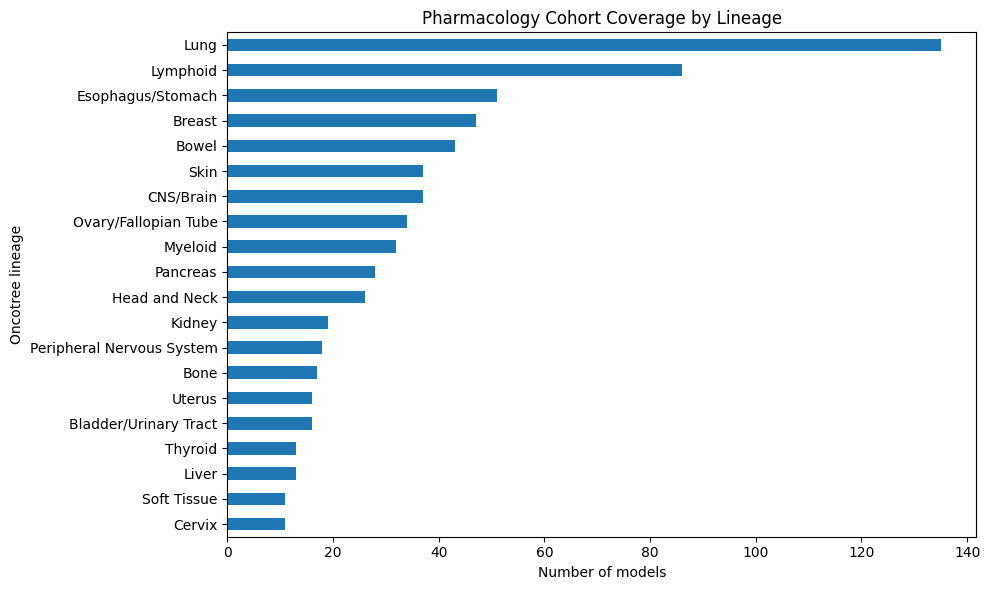

In [10]:
# =============================================================================
# Top represented lineages
# =============================================================================

plt.figure(figsize=(10, 6))

lineage_counts.head(20).sort_values().plot(kind="barh")

plt.xlabel("Number of models")
plt.ylabel("Oncotree lineage")
plt.title("Pharmacology Cohort Coverage by Lineage")

plt.tight_layout()
plt.show()

In [11]:
drug_coverage = (
    gdsc_eligible.groupby("DRUG_NAME")["SANGER_MODEL_ID"]
    .nunique()
    .sort_values(ascending=False)
)

drug_coverage.describe()

count    286.000000
mean     613.587413
std      128.344374
min      136.000000
25%      552.000000
50%      655.000000
75%      703.000000
max      712.000000
Name: SANGER_MODEL_ID, dtype: float64

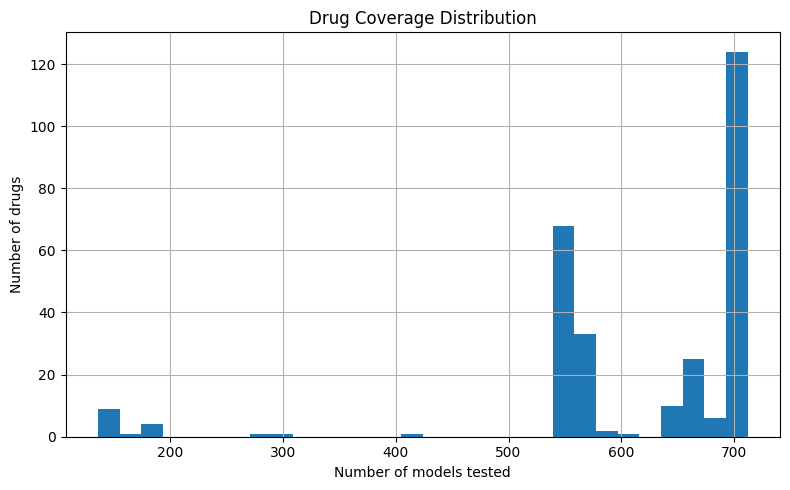

In [12]:
# =============================================================================
# Drug coverage distribution
# =============================================================================

plt.figure(figsize=(8, 5))

drug_coverage.hist(bins=30)

plt.xlabel("Number of models tested")
plt.ylabel("Number of drugs")
plt.title("Drug Coverage Distribution")

plt.tight_layout()
plt.show()

In [13]:
# =============================================================================
# Lowest coverage drugs
# =============================================================================

drug_coverage.sort_values().head(20)

DRUG_NAME
Tretinoin         136
CCT-018159        136
Bicalutamide      136
SL0101            136
Elesclomol        136
CHIR-99021        136
Piperlongumine    136
IOX2              136
BX795             136
SB505124          170
AZD6482           175
GSK269962A        176
Tozasertib        176
PF-4708671        176
TW 37             281
Remodelin         298
Daporinad         411
Nelarabine        549
Eg5_9814          549
776928            549
Name: SANGER_MODEL_ID, dtype: int64

In [14]:
pathway_counts = (
    gdsc_eligible["PATHWAY_NAME"]
    .value_counts()
)

display(pathway_counts)

PATHWAY_NAME
Unclassified                         19235
PI3K/MTOR signaling                  16841
Other                                16082
DNA replication                      13218
Other, kinases                       12828
ERK MAPK signaling                    9911
Genome integrity                      8973
Cell cycle                            8612
Apoptosis regulation                  8067
Chromatin histone methylation         8028
RTK signaling                         7767
Chromatin other                       6370
Chromatin histone acetylation         6113
WNT signaling                         5576
Protein stability and degradation     5143
EGFR signaling                        4941
Mitosis                               4769
IGF1R signaling                       4073
Metabolism                            3565
Hormone-related                       2799
p53 pathway                           2774
Cytoskeleton                          2546
JNK and p38 signaling                 140

In [15]:
target_counts = (
    gdsc_eligible["PUTATIVE_TARGET"]
    .value_counts()
)

display(target_counts.head(30))

PUTATIVE_TARGET
PARP1, PARP2                3460
MEK1, MEK2                  3364
TOP1                        3222
EGFR                        2814
TNKS1, TNKS2                2714
AKT1, AKT2, AKT3            2485
DOT1L                       2113
IGF1R, IR                   2108
BRAF                        2100
ATR                         2054
PORCN                       2021
ERK1, ERK2                  1986
DNA alkylating agent        1969
Microtubule stabiliser      1928
BRD4                        1906
Antimetabolite              1778
MCL1                        1702
Mutant RAS                  1701
HSP90                       1677
EGFR, ERBB2                 1418
FGFR1, FGFR2, FGFR3         1415
CDK4, CDK6                  1414
IGF1R                       1413
MDM2                        1407
PI3K (beta sparing)         1407
PI3Kalpha                   1400
BRD2, BRD3, BRD4            1310
SYK                         1310
MTORC1, MTORC2              1281
Microtubule destabiliser   

In [16]:
print(
    "Unique targets:",
    gdsc_eligible["PUTATIVE_TARGET"].nunique()
)

Unique targets: 185


## Pharmacological Metadata Summary

The integrated pharmacogenomic layer retains pharmacological measurements exclusively from models belonging to the eligible transcriptomic cohort.

Drug coverage, pathway representation, and putative target annotations were assessed within this restricted analytical dataset rather than across the complete GDSC2 source.

Drug-response coverage varies across compounds, indicating that not all models have been evaluated against the same pharmacological agents. This heterogeneity must be considered when defining downstream analytical subsets and constructing resistance-like phenotypes.

Pathway and putative target annotations provide complementary information for organizing compounds into pharmacological groups. However, compounds sharing targets or biological pathways may exhibit statistical and biological dependencies that must be accounted for during downstream analyses.

These dependencies represent potential sources of information leakage when related compounds are distributed across training and validation partitions. Consequently, drug-family-aware grouping and leakage controls will be required in subsequent analytical stages.

No pharmacological response phenotypes, drug-family assignments, or biological associations are inferred at this integration stage.

In [17]:
# =============================================================================
# Build output artifacts
# =============================================================================

integrated_pharmacology_cohort = pharmacology_cohort.copy()

drug_metadata = (
    gdsc_eligible[
        ["DRUG_ID", "DRUG_NAME", "PUTATIVE_TARGET", "PATHWAY_NAME"]
    ]
    .drop_duplicates()
    .sort_values(["DRUG_ID", "DRUG_NAME"])
    .reset_index(drop=True)
)

drug_response = gdsc_eligible[
    [
        "SANGER_MODEL_ID",
        "DRUG_ID",
        "DRUG_NAME",
        "PUTATIVE_TARGET",
        "PATHWAY_NAME",
        "LN_IC50",
        "AUC",
        "Z_SCORE",
        "RMSE",
    ]
].copy()

assert len(drug_response) == len(gdsc_eligible)
assert set(drug_response["DRUG_ID"]) == set(drug_metadata["DRUG_ID"])

print("Integrated pharmacology cohort:", integrated_pharmacology_cohort.shape)
print("Drug metadata:", drug_metadata.shape)
print("Drug response:", drug_response.shape)

Integrated pharmacology cohort: (712, 8)
Drug metadata: (295, 4)
Drug response: (180335, 9)


In [18]:
# =============================================================================
# Save outputs
# =============================================================================

OUTPUT_DIR = Paths.pharmacology
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

integrated_pharmacology_cohort.to_csv(
    OUTPUT_DIR / "306_integrated_pharmacology_cohort.csv",
    index=False
)

drug_metadata.to_csv(
    OUTPUT_DIR / "306_drug_metadata.csv",
    index=False
)

drug_response.to_csv(
    OUTPUT_DIR / "306_gdsc_drug_response.csv",
    index=False
)

print("Files saved:")
print("- 306_integrated_pharmacology_cohort.csv")
print("- 306_drug_metadata.csv")
print("- 306_gdsc_drug_response.csv")

Files saved:
- 306_integrated_pharmacology_cohort.csv
- 306_drug_metadata.csv
- 306_gdsc_drug_response.csv
